# GSE62832

> - Author: Cao Qiang
> - Email: qiangcao2014@gmail.com
> - Created: 2020-05-03
> - Modified: 2023-09-27

# 1. Experimental Design

> The effects of moderate weight gain in adipose tissue gene expression in metabolically-normal (MNO) and metabolically-abnormal (MAO) subjects.
> - Fabbrini E, Yoshino J, Yoshino M, Magkos F, Tiemann Luecking C, Samovski D, Fraterrigo G, Okunade AL, Patterson BW, Klein S. Metabolically normal obese people are protected from adverse effects following weight gain. J Clin Invest. 2015 Feb;125(2):787-95. doi: 10.1172/JCI78425.
> - GPL6244: GeneChip Human Gene 1.0 ST Array (Affymetrix)
> - Affymetrix GeneChip 7G 3000

| Sample | Organism | Tissue | Metabolic Status | Treatment | Replicate |
| - | - | - | - | - | - |
| MAO-Pre | Homo sapiens | Subcutaneous adipose | metabolically abnormal obese (MAO) | pre-gaining weight | rep1~8 |
| MAO-Post | Homo sapiens | Subcutaneous adipose | metabolically abnormal obese (MAO) | post gaining weight | rep1~8 |
| MNO-Pre | Homo sapiens | Subcutaneous adipose | metabolically normal obese (MNO) | pre-gaining weight | rep1~12 |
| MNO-Post | Homo sapiens | Subcutaneous adipose | metabolically normal obese (MNO) | post gaining weight | rep1~12 |

In [ ]:
library(tidyverse)
suppressPackageStartupMessages(library(GEOquery))
suppressPackageStartupMessages(library(hugene10sttranscriptcluster.db))
suppressPackageStartupMessages(library(pheatmap))
suppressPackageStartupMessages(library(ggfortify))
suppressPackageStartupMessages(library(limma))
suppressPackageStartupMessages(library(clusterProfiler))
suppressPackageStartupMessages(library(org.Hs.eg.db))
suppressPackageStartupMessages(library(enrichplot))
suppressPackageStartupMessages(library(pathview))
suppressPackageStartupMessages(library(cowplot))

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.2     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.1     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


# 2. Download Data

In [2]:
gse_id <- "GSE62832"
data_dir <- file.path("~/dataset_1/expression_dataset/array", gse_id)
dir.create(data_dir, showWarnings = FALSE)

In [3]:
eSet <- getGEO(
    GEO = gse_id, destdir = data_dir,
    AnnotGPL = TRUE, getGPL = TRUE)[[1]]
eSet

Found 1 file(s)

GSE62832_series_matrix.txt.gz



ExpressionSet (storageMode: lockedEnvironment)
assayData: 33297 features, 36 samples 
  element names: exprs 
protocolData: none
phenoData
  sampleNames: GSM1534034 GSM1534035 ... GSM1534069 (36 total)
  varLabels: title geo_accession ... tissue:ch1 (35 total)
  varMetadata: labelDescription
featureData
  featureNames: 7892501 7892502 ... 8180418 (33297 total)
  fvarLabels: ID Gene title ... GO:Component ID (21 total)
  fvarMetadata: Column Description labelDescription
experimentData: use 'experimentData(object)'
  pubMedIds: 25555214 
Annotation: GPL6244 

In [4]:
exprs(eSet)[1:6, 1:6]

,GSM1534034,GSM1534035,GSM1534036,GSM1534037,GSM1534038,GSM1534039
7892501,2.916540,2.930378,2.284593,3.872071,3.264518,2.694068
7892502,3.389937,4.042295,4.233018,3.910171,3.955966,4.191598
7892503,2.085829,2.083128,2.132488,2.322827,2.834962,2.648801
7892504,9.098609,9.287103,9.216679,9.392648,8.872817,9.367094
7892505,3.431813,2.044456,1.488578,2.429538,2.470807,1.671577
7892506,1.741363,2.139848,1.829892,1.752936,1.839485,1.999294


In [5]:
pdata <- pData(eSet) |> 
    tidyr::separate(title, into = c("ID", "Treatment"), sep = "-", remove = FALSE) |>
    dplyr::rename(Status = `metabolic status:ch1`) |>
    dplyr::select("title", "ID", "Treatment", "Status") |>
    mutate(
        Treatment = factor(Treatment, levels = c("Pre", "Post")),
        Status = factor(Status, levels = c("MNO", "MAO")))
head(pdata)

,title,ID,Treatment,Status
,<chr>,<chr>,<fct>,<fct>
GSM1534034,OV12-Pre,OV12,Pre,MAO
GSM1534035,OV12-Post,OV12,Post,MAO
GSM1534036,OV17-Pre,OV17,Pre,MAO
GSM1534037,OV17-Post,OV17,Post,MAO
GSM1534038,OV43-Pre,OV43,Pre,MAO
GSM1534039,OV43-Post,OV43,Post,MAO


# 3. Convert Probe to Symbol

## a). GPL Annotation

In [6]:
gpl <- getGEO(filename = file.path(data_dir, "GPL6244.annot.gz"))
gpl

An object of class "GPL"
date 
[1] "Aug 09 2016"
platform 
[1] "GPL6244"
platform_organism 
[1] "Homo sapiens"
platform_title 
[1] "[HuGene-1_0-st] Affymetrix Human Gene 1.0 ST Array [transcript (gene) version]"
An object of class "GEODataTable"
****** Column Descriptions ******
                  Column                         Description
1                     ID         ID from Platform data table
2             Gene title                    Entrez Gene name
3            Gene symbol                  Entrez Gene symbol
4                Gene ID              Entrez Gene identifier
5          UniGene title                 Entrez UniGene name
6         UniGene symbol               Entrez UniGene symbol
7             UniGene ID           Entrez UniGene identifier
8       Nucleotide Title             Entrez Nucleotide title
9                     GI                  GenBank identifier
10     GenBank Accession                   GenBank accession
11      Platform_CLONEID   CLONE_ID from Platform

In [7]:
gpl_table <- Table(gpl)
gpl_table |> select("ID", "Gene symbol") |> head()

,ID,Gene symbol
,<int>,<chr>
1,7896736,
2,7896738,
3,7896740,OR4F17///OR4F5///OR4F4
4,7896742,LOC100134822///SEPT14///LINC00266-1///PCMTD2
5,7896744,OR4F29///OR4F21///OR4F16///OR4F3
6,7896746,


In [8]:
probe2symbol <- gpl_table |>
    dplyr::select("ID", "Gene symbol") |>
    dplyr::rename(probe_id = ID, symbol = `Gene symbol`) |>
    mutate(probe_id = as.character(probe_id))

In [9]:
exprMat <- exprs(eSet) |> 
    as.data.frame() |> 
    rownames_to_column("probe_id") |>
    inner_join(probe2symbol, by = "probe_id") |>
    filter(symbol != "" & !is.na(symbol)) |>
    separate_rows(symbol, sep = "///") |>
    group_by(symbol) |>
    summarise(across(where(is.numeric), \(x) max(x, na.rm = TRUE))) |>
    column_to_rownames("symbol") |>
    as.matrix()

In [10]:
exprMat[1:6, 1:6]

,GSM1534034,GSM1534035,GSM1534036,GSM1534037,GSM1534038,GSM1534039
1060P11.3,4.734193,3.778365,3.798707,4.075211,3.954811,4.286553
A1BG,5.243725,5.284775,4.943841,5.255176,5.058006,4.745804
A1CF,3.677696,3.311106,3.002596,3.132491,3.384748,3.132063
A2M,10.458070,10.675110,10.532140,10.489020,10.464930,10.594130
A2ML1,4.152457,3.287877,3.615037,3.955980,3.854978,3.582998
A3GALT2,4.179140,3.706264,3.703924,3.846446,3.801070,3.929850


## b). R Package

In [12]:
ls("package:hugene10sttranscriptcluster.db")

[1] "hugene10sttranscriptcluster"             
 [2] "hugene10sttranscriptcluster_dbconn"      
 [3] "hugene10sttranscriptcluster_dbfile"      
 [4] "hugene10sttranscriptcluster_dbInfo"      
 [5] "hugene10sttranscriptcluster_dbschema"    
 [6] "hugene10sttranscriptcluster.db"          
 [7] "hugene10sttranscriptclusterACCNUM"       
 [8] "hugene10sttranscriptclusterALIAS2PROBE"  
 [9] "hugene10sttranscriptclusterCHR"          
[10] "hugene10sttranscriptclusterCHRLENGTHS"   
[11] "hugene10sttranscriptclusterCHRLOC"       
[12] "hugene10sttranscriptclusterCHRLOCEND"    
[13] "hugene10sttranscriptclusterENSEMBL"      
[14] "hugene10sttranscriptclusterENSEMBL2PROBE"
[15] "hugene10sttranscriptclusterENTREZID"     
[16] "hugene10sttranscriptclusterENZYME"       
[17] "hugene10sttranscriptclusterENZYME2PROBE" 
[18] "hugene10sttranscriptclusterGENENAME"     
[19] "hugene10sttranscriptclusterGO"           
[20] "hugene10sttranscriptclusterGO2ALLPROBES" 
[21] "hugene10sttranscriptclusterGO2PROBE"     
[22] "hugene10sttranscriptclusterMAP"          
[23] "hugene10sttranscriptclusterMAPCOUNTS"    
[24] "hugene10sttranscriptclusterOMIM"         
[25] "hugene10sttranscriptclusterORGANISM"     
[26] "hugene10sttranscriptclusterORGPKG"       
[27] "hugene10sttranscriptclusterPATH"         
[28] "hugene10sttranscriptclusterPATH2PROBE"   
[29] "hugene10sttranscriptclusterPFAM"         
[30] "hugene10sttranscriptclusterPMID"         
[31] "hugene10sttranscriptclusterPMID2PROBE"   
[32] "hugene10sttranscriptclusterPROSITE"      
[33] "hugene10sttranscriptclusterREFSEQ"       
[34] "hugene10sttranscriptclusterSYMBOL"       
[35] "hugene10sttranscriptclusterUNIPROT"

In [13]:
probe2symbol <- toTable(hugene10sttranscriptclusterSYMBOL)
head(probe2symbol)

,probe_id,symbol
,<chr>,<chr>
1,7896746,MTND1P23
2,7896754,SEPTIN7P13
3,7896759,LINC01128
4,7896761,SAMD11
5,7896779,KLHL17
6,7896798,PLEKHN1


In [14]:
exprMat2 <- exprs(eSet) |> 
    as.data.frame() |> 
    rownames_to_column("probe_id") |>
    inner_join(probe2symbol, by = "probe_id") |>
    filter(symbol != "" & !is.na(symbol)) |>
    group_by(symbol) |>
    summarise(across(where(is.numeric), \(x) max(x, na.rm = TRUE))) |>
    column_to_rownames("symbol") |>
    as.matrix()

In [15]:
exprMat2[1:6, 1:6]

,GSM1534034,GSM1534035,GSM1534036,GSM1534037,GSM1534038,GSM1534039
A1CF,3.677696,3.311106,3.002596,3.132491,3.384748,3.132063
A2M,10.458070,10.675110,10.532140,10.489020,10.464930,10.594130
A2ML1,4.152457,3.287877,3.615037,3.955980,3.854978,3.582998
A3GALT2,4.179140,3.706264,3.703924,3.846446,3.801070,3.929850
A4GALT,5.080706,5.208633,5.114419,5.163810,4.991917,5.206988
A4GNT,3.925665,3.618792,3.382124,3.394501,3.883694,3.505180


# 4. Data Exploration

## 1). Quality Control

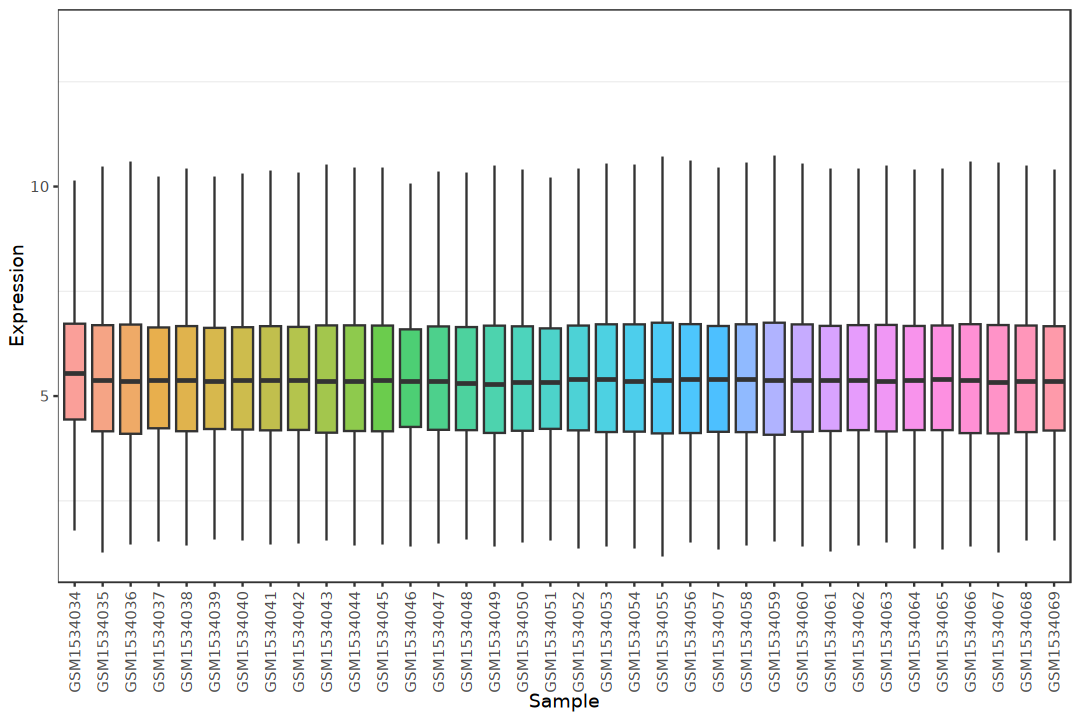

In [16]:
options(repr.plot.width = 9, repr.plot.height = 6)
exprMat |> as.data.frame() |> 
    rownames_to_column("symbol") |>
    pivot_longer(-symbol, names_to = "sample", values_to = "value") |>
    ggplot(aes(x = sample, y = value)) +
        geom_boxplot(aes(fill = sample), alpha = 0.7, outlier.shape = NA) +
        labs(x = 'Sample', y = 'Expression') +
        theme_bw() +
        theme(
            legend.position = "none", 
            panel.grid.major = element_blank(),
            axis.text.x = element_text(angle = 90, vjust = 0.5, hjust = 1))

## 2). Housekeeping Genes

In [17]:
HOUSEKEEPING_GENES <- readLines(
    "~/reference/Database/Housekeeping_Genes/HOUNKPE_HOUSEKEEPING_GENES.v2026.1.Hs.gmt", 
    warn = FALSE) |> 
    str_split("\t") |>
    (\(x) x[[1]])() |>
    (\(x) x[-c(1,2)])() |>
    unique()

In [18]:
str(HOUSEKEEPING_GENES)

 chr [1:1129] "AAMP" "AAR2" "AARS1" "AARSD1" "AASDHPPT" "ABCE1" "ABCF2" ...


In [19]:
anno_col <- data.frame(row.names = rownames(pdata),
    Treat = pdata$Treatment, Status = pdata$Status)

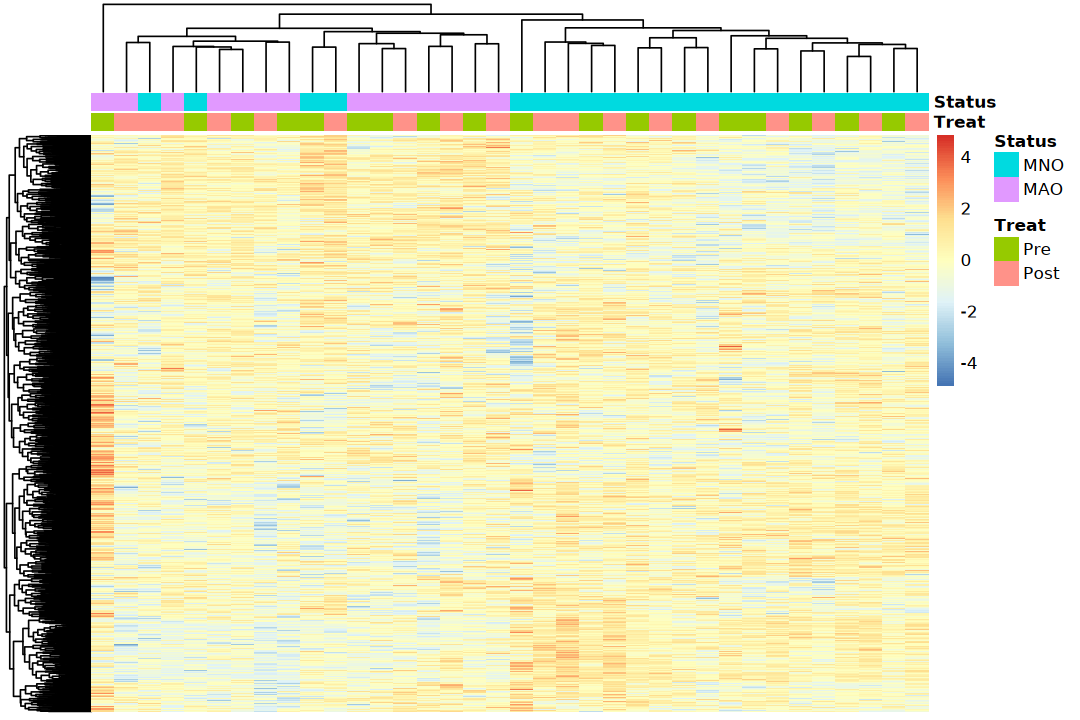

In [20]:
options(repr.plot.width = 9, repr.plot.height = 6)

pheatmap(exprMat[rownames(exprMat) %in% HOUSEKEEPING_GENES, ],
         scale = 'row', annotation_col = anno_col,
         show_rownames = FALSE, show_colnames = FALSE)

## 3). PCA

In [22]:
gene_sd <- apply(exprMat, 1, sd)
top_genes <- names(sort(gene_sd, decreasing = TRUE))[1:1000]

Warning message:
“`aes_string()` was deprecated in ggplot2 3.0.0.
ℹ Please use tidy evaluation idioms with `aes()`.
ℹ See also `vignette("ggplot2-in-packages")` for more information.
ℹ The deprecated feature was likely used in the ggfortify package.
  Please report the issue at <https://github.com/sinhrks/ggfortify/issues>.”


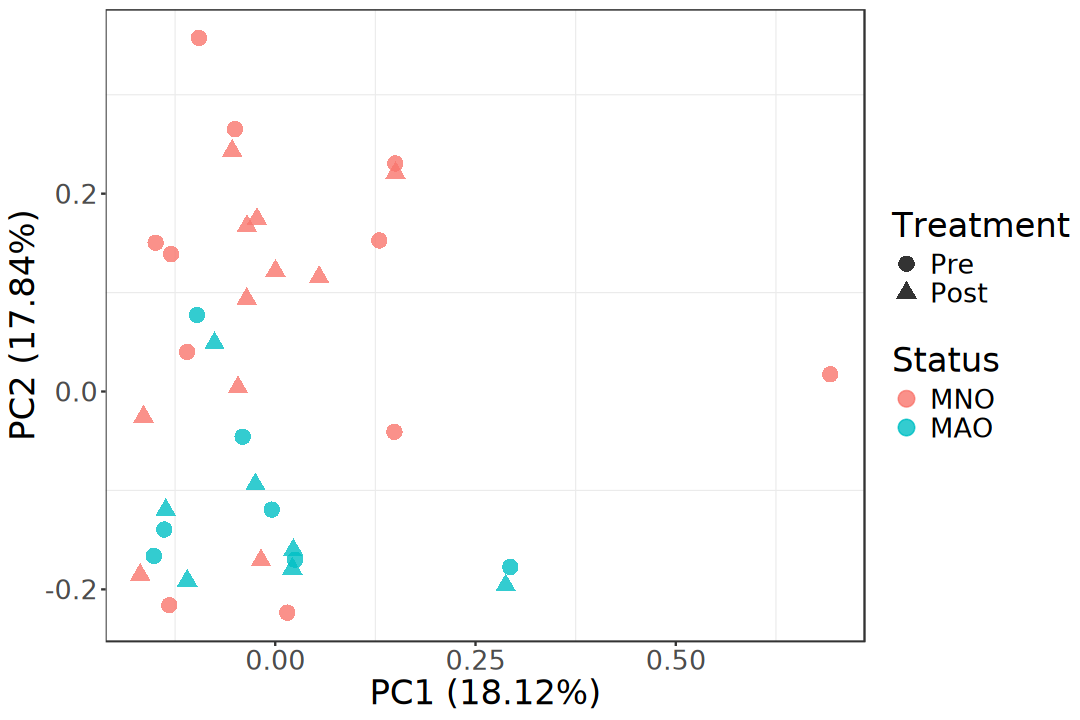

In [23]:
options(repr.plot.width = 9, repr.plot.height = 6)
    exprMat[top_genes, ] |> t() |>
    prcomp() |> 
    autoplot(data = pdata, colour = "Status", shape = "Treatment", 
        size = 4, alpha = 0.8) +
    theme_bw() +
    theme(
        legend.title = element_text(size = 20),
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 20),
        axis.text = element_text(size = 16), 
        panel.grid.major = element_blank())

# 5. Differential Analysis

## Limma

In [25]:
design <- model.matrix(~ 0 + pdata$Status)

colnames(design) <- levels(pdata$Status)

rownames(design) <- colnames(exprMat)

In [26]:
contrast <- makeContrasts(
    paste0(levels(pdata$Status), collapse = "-"),
    levels = design)
contrast

,MNO-MAO
MNO,1
MAO,-1


In [27]:
fit <- lmFit(exprMat, design)
fit <- contrasts.fit(fit, contrast)
fit <- eBayes(fit)
deg <- topTable(fit, number = Inf)

In [28]:
p_cutoff <- 0.05
logFC_cutoff <- with(deg, mean(abs(logFC)) + 2*sd(abs(logFC)))
# logFC_cutoff <- 1

In [29]:
deg <- topTable(fit, number = Inf) |> 
    dplyr::rename(padj = adj.P.Val, pvalue = P.Value) |>
    mutate(
        result = case_when(
            pvalue < p_cutoff & logFC >  logFC_cutoff ~ "Up",
            pvalue < p_cutoff & logFC < -logFC_cutoff ~ "Down",
            TRUE ~ "NotSig") |> 
            factor(levels = c("Up", "Down", "NotSig")))

In [30]:
head(deg)
table(deg$result)

,logFC,AveExpr,t,pvalue,padj,B,result
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
SYNM,-0.4413670,6.732988,-7.312505,7.858998e-09,8.917941e-05,10.020223,Down
RPS15,0.4191768,10.843180,7.218754,1.055580e-08,8.917941e-05,9.748975,Up
WDR83OS,0.4730807,8.646015,7.161315,1.265136e-08,8.917941e-05,9.582361,Up
CSNK2B,0.3373858,9.652101,6.990255,2.172540e-08,1.148568e-04,9.084362,Up
TK2,-0.3175659,8.268434,-6.849056,3.399725e-08,1.437880e-04,8.671407,Down
HTATSF1,-0.3429697,7.690746,-6.667050,6.065551e-08,1.587943e-04,8.136857,Down



    Up   Down NotSig 
   372    248  20527 

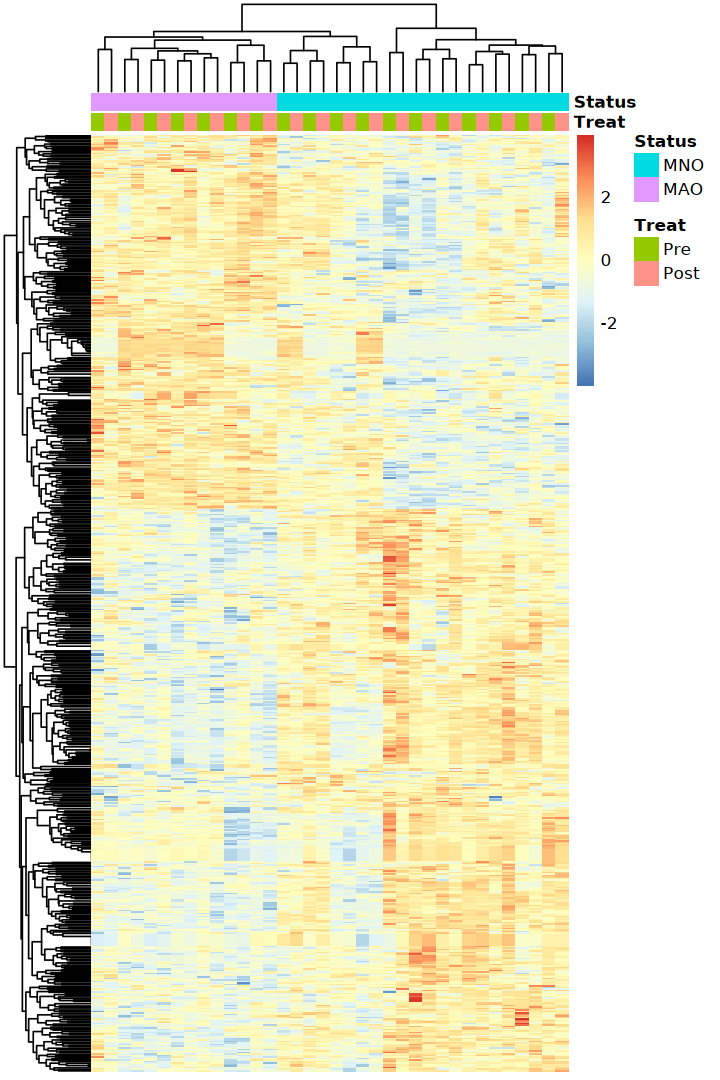

In [31]:
options(repr.plot.width = 6, repr.plot.height = 9)

pheatmap(exprMat[rownames(exprMat) %in% rownames(deg[deg$result != 'NotSig', ]), ],
         scale = 'row', annotation_col = anno_col,
         show_rownames = FALSE, show_colnames = FALSE)

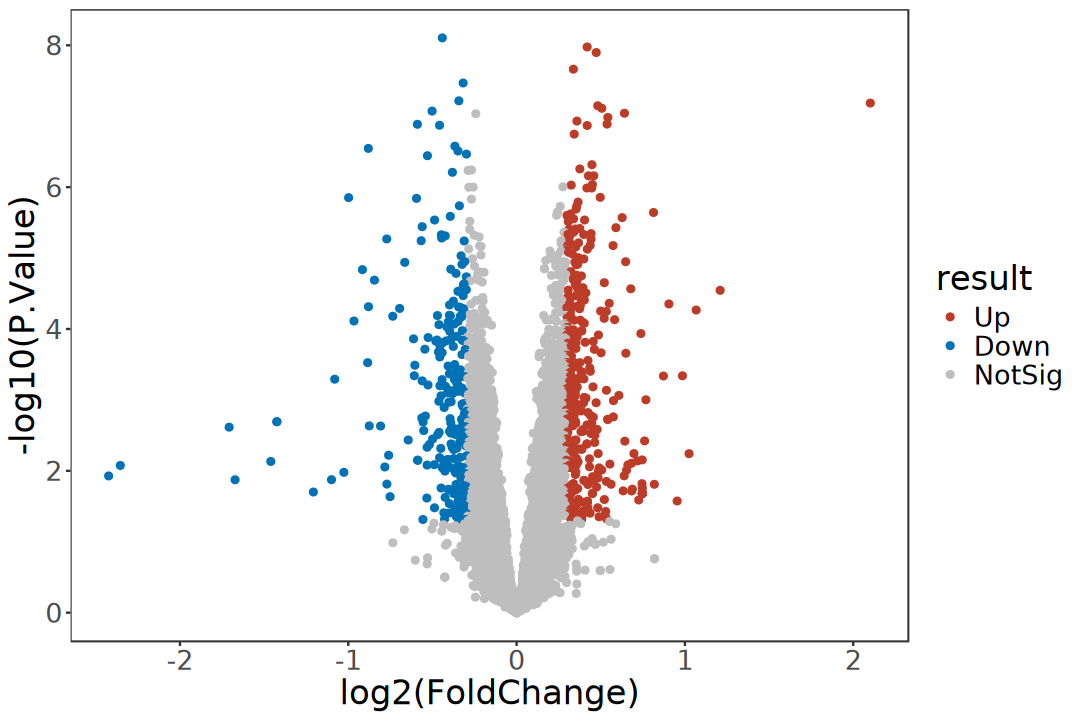

In [32]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(deg, aes(logFC, -log10(pvalue), color = result)) +
    geom_point() +
    scale_color_manual(values = c("#BC3C28", "#0072B5", "grey")) +
    labs(x = "log2(FoldChange)", y = "-log10(P.Value)") +
    theme_bw() +
    theme(panel.grid = element_blank(), 
        legend.title = element_text(size = 20), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 20),
        axis.text = element_text(size = 16))

# 6. Gene Function Analysis

In [34]:
gene_id <- bitr(
    rownames(deg), OrgDb = org.Hs.eg.db, 
    fromType = "SYMBOL", toType = c("ENTREZID"))
head(gene_id)

'select()' returned 1:many mapping between keys and columns

Warning message in bitr(rownames(deg), OrgDb = org.Hs.eg.db, fromType = "SYMBOL", :
“7.15% of input gene IDs are fail to map...”


,SYMBOL,ENTREZID
,<chr>,<chr>
1,SYNM,23336
2,RPS15,6209
3,WDR83OS,51398
4,CSNK2B,1460
5,TK2,7084
6,HTATSF1,27336


In [35]:
deg <- deg |> rownames_to_column("SYMBOL") |> 
    inner_join(gene_id, by = "SYMBOL") |>
    arrange(pvalue) |>
    distinct(SYMBOL, .keep_all = TRUE)
head(deg)

,SYMBOL,logFC,AveExpr,t,pvalue,padj,B,result,ENTREZID
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
1,SYNM,-0.4413670,6.732988,-7.312505,7.858998e-09,8.917941e-05,10.020223,Down,23336
2,RPS15,0.4191768,10.843180,7.218754,1.055580e-08,8.917941e-05,9.748975,Up,6209
3,WDR83OS,0.4730807,8.646015,7.161315,1.265136e-08,8.917941e-05,9.582361,Up,51398
4,CSNK2B,0.3373858,9.652101,6.990255,2.172540e-08,1.148568e-04,9.084362,Up,1460
5,TK2,-0.3175659,8.268434,-6.849056,3.399725e-08,1.437880e-04,8.671407,Down,7084
6,HTATSF1,-0.3429697,7.690746,-6.667050,6.065551e-08,1.587943e-04,8.136857,Down,27336


## GO Analysis

In [36]:
ego <- enrichGO(
    gene = deg[deg$result == "Up", ]$ENTREZID, 
    universe = deg$ENTREZID, OrgDb = org.Hs.eg.db, 
    ont = "BP", readable = TRUE, pAdjustMethod = "BH", 
    pvalueCutoff = 0.05, qvalueCutoff = 0.05)

In [37]:
ego |> as.data.frame() |> 
    select(ID, Description, GeneRatio, FoldEnrichment, pvalue, p.adjust) |> 
    head()

,ID,Description,GeneRatio,FoldEnrichment,pvalue,p.adjust
,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>
GO:0006091,GO:0006091,generation of precursor metabolites and energy,30/302,3.761799,4.908735e-10,1.511890e-06
GO:0015980,GO:0015980,energy derivation by oxidation of organic compounds,27/302,3.907164,1.670354e-09,2.572346e-06
GO:0009060,GO:0009060,aerobic respiration,20/302,4.313139,4.621781e-08,4.745028e-05
GO:0045333,GO:0045333,cellular respiration,21/302,3.972357,8.715593e-08,6.711007e-05
GO:0019646,GO:0019646,aerobic electron transport chain,11/302,7.816183,1.461757e-07,9.004426e-05
GO:0042773,GO:0042773,ATP synthesis coupled electron transport,11/302,7.172497,3.584507e-07,1.476470e-04


Warning message in (function (model, data, ...) :
“Arguments in `...` must be used.
✖ Problematic argument:
• by = "Count"
ℹ Did you misspell an argument name?”


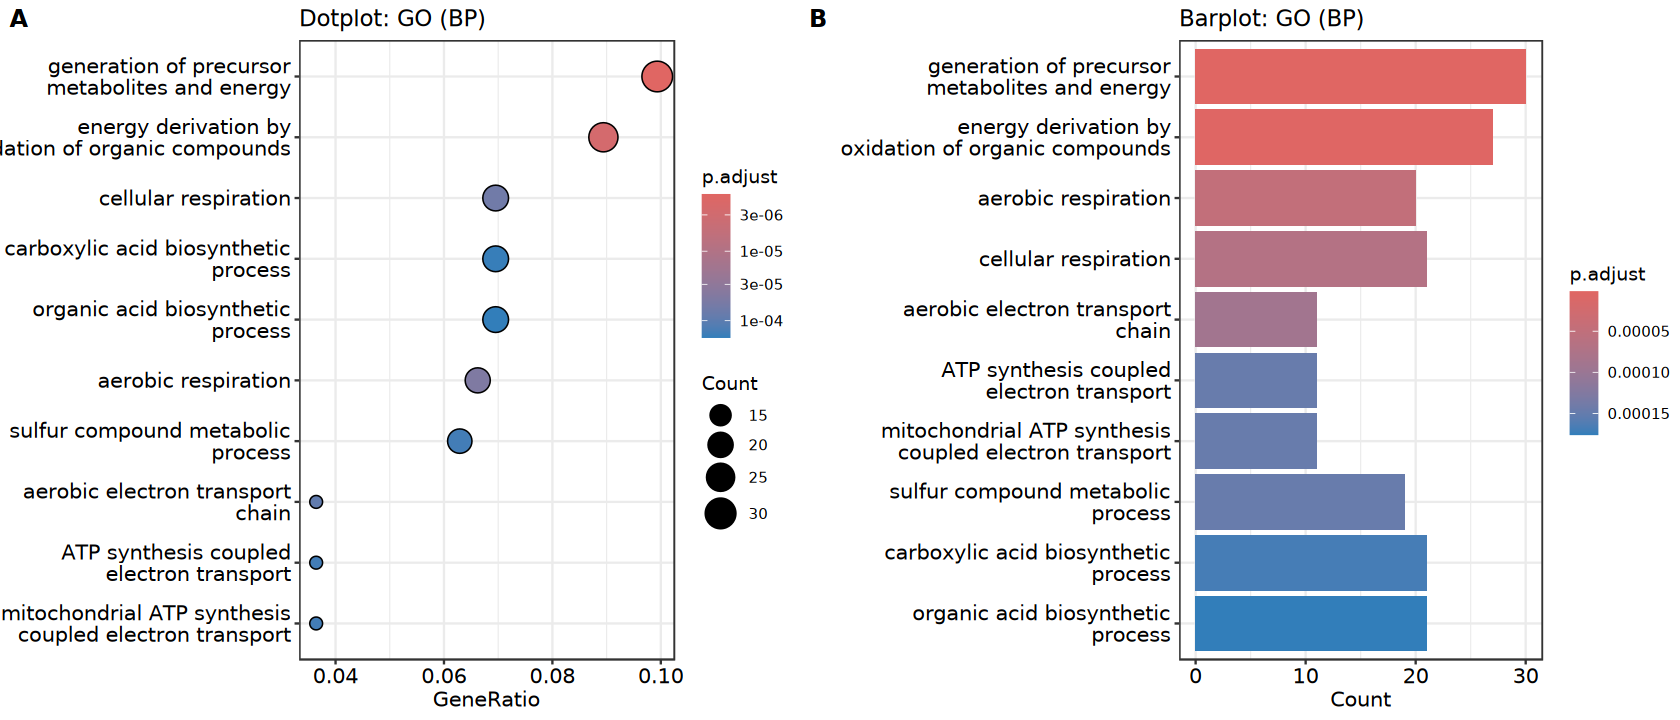

In [38]:
options(repr.plot.width = 14, repr.plot.height = 6)

p1 <- dotplot(ego, title = "Dotplot: GO (BP)", font.size = 12)
p2 <- barplot(ego, showCategory = 10, title = "Barplot: GO (BP)", font.size = 12)
blank <- ggplot() + theme_void()

plot_grid(p1, blank, p2, ncol = 3, labels = c("A", "B"), 
    rel_widths = c(1, 0.1, 1))

## KEGG Analysis

In [39]:
ekegg <- enrichKEGG(
    gene = deg[deg$result == "Up", ]$ENTREZID, 
    universe = deg$ENTREZID, organism = 'hsa',
    pAdjustMethod = "BH", 
    pvalueCutoff = 0.05, qvalueCutoff = 0.05)

Reading KEGG annotation online: "https://rest.kegg.jp/link/hsa/pathway"...

Reading KEGG annotation online: "https://rest.kegg.jp/list/pathway/hsa"...



In [40]:
ekegg |> as.data.frame() |> 
    select(ID, Description, GeneRatio, FoldEnrichment, pvalue, p.adjust) |> 
    head()

,ID,Description,GeneRatio,FoldEnrichment,pvalue,p.adjust
,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>
hsa00190,hsa00190,Oxidative phosphorylation,12/176,5.436189,1.819229e-06,0.0004093266
hsa05016,hsa05016,Huntington disease,19/176,3.231621,5.953727e-06,0.0006697943
hsa04932,hsa04932,Non-alcoholic fatty liver disease,13/176,4.110586,1.545130e-05,0.0009415346
hsa05415,hsa05415,Diabetic cardiomyopathy,14/176,3.747676,2.077781e-05,0.0009415346
hsa01212,hsa01212,Fatty acid metabolism,8/176,6.730519,2.092299e-05,0.0009415346
hsa00100,hsa00100,Steroid biosynthesis,5/176,11.778409,4.871644e-05,0.0017726799


Warning message in (function (model, data, ...) :
“Arguments in `...` must be used.
✖ Problematic argument:
• by = "Count"
ℹ Did you misspell an argument name?”


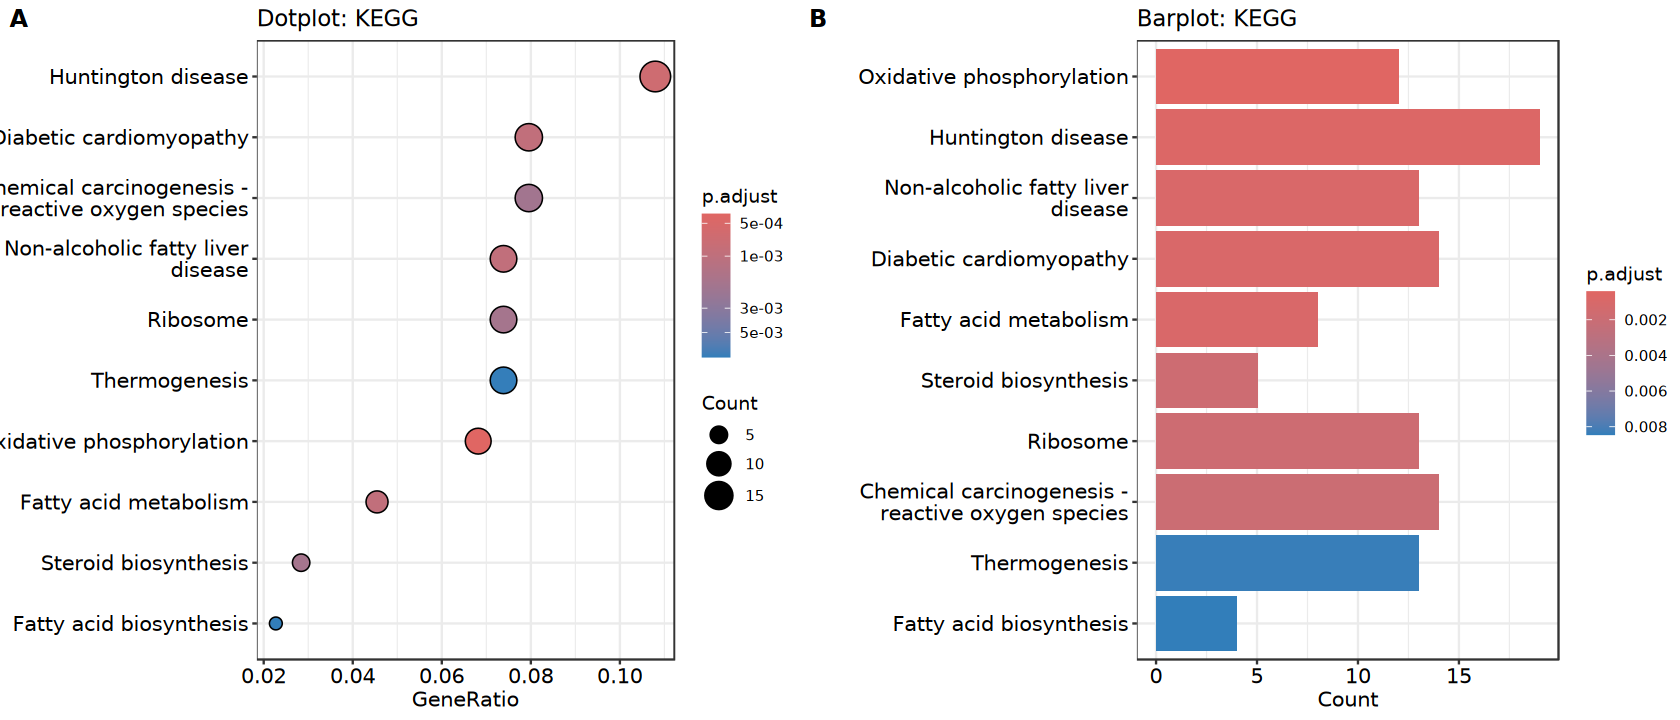

In [41]:
options(repr.plot.width = 14, repr.plot.height = 6)

p1 <- dotplot(ekegg, title = "Dotplot: KEGG", font.size = 12)
p2 <- barplot(ekegg, showCategory = 10, title = "Barplot: KEGG", font.size = 12)
blank <- ggplot() + theme_void()

plot_grid(p1, blank, p2, ncol = 3, labels = c("A", "B"), 
    rel_widths = c(1, 0.1, 1))

## GSEA Analysis

In [42]:
gene_rank <- deg$logFC
names(gene_rank) <- deg$ENTREZID
gene_rank <- sort(gene_rank, decreasing = TRUE)

In [43]:
gsea_go <- gseGO(geneList = gene_rank, OrgDb = org.Hs.eg.db, ont = "BP")

using 'fgsea' for GSEA analysis, please cite Korotkevich et al (2019).


preparing geneSet collections...

GSEA analysis...

Warning message in preparePathwaysAndStats(pathways, stats, minSize, maxSize, gseaParam, :
“There are ties in the preranked stats (5.01% of the list).
The order of those tied genes will be arbitrary, which may produce unexpected results.”
Warning message in fgseaMultilevel(pathways = pathways, stats = stats, minSize = minSize, :
“For some of the pathways the P-values were likely overestimated. For such pathways log2err is set to NA.”
Warning message in fgseaMultilevel(pathways = pathways, stats = stats, minSize = minSize, :
“For some pathways, in reality P-values are less than 1e-10. You can set the `eps` argument to zero for better estimation.”
leading edge analysis...

done...



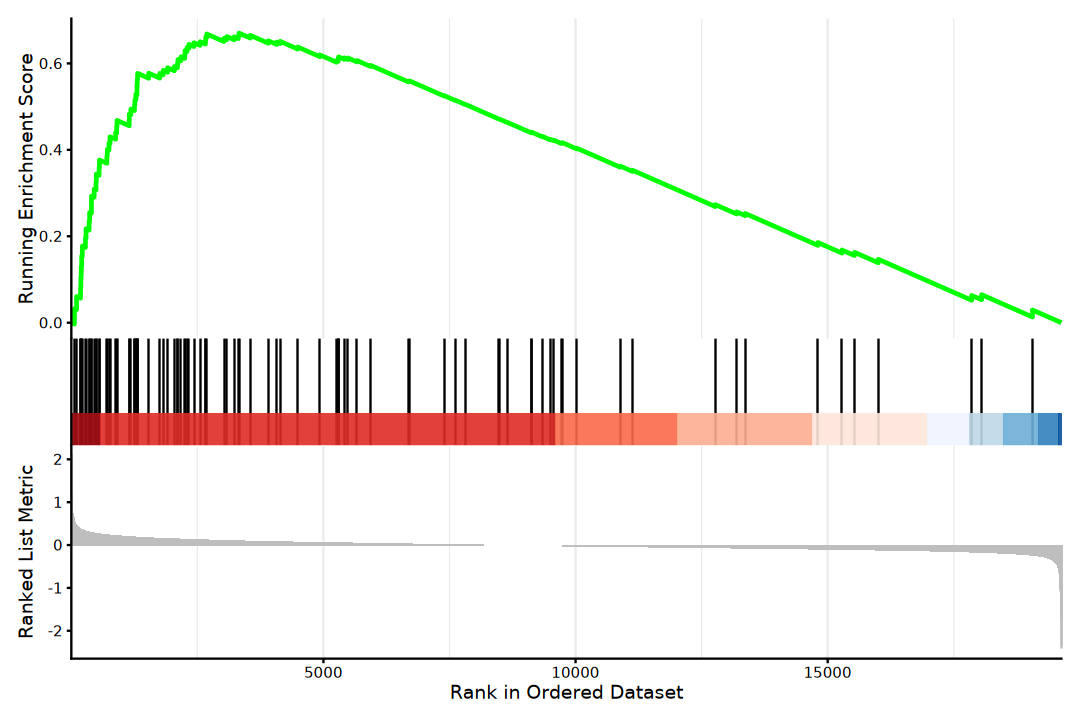

In [44]:
options(repr.plot.width = 9, repr.plot.height = 6)
gseaplot2(gsea_go, geneSetID = 1)

In [45]:
gsea_kegg <- gseKEGG(geneList = gene_rank, organism = 'hsa')

using 'fgsea' for GSEA analysis, please cite Korotkevich et al (2019).


preparing geneSet collections...

GSEA analysis...

Warning message in preparePathwaysAndStats(pathways, stats, minSize, maxSize, gseaParam, :
“There are ties in the preranked stats (5.01% of the list).
The order of those tied genes will be arbitrary, which may produce unexpected results.”
Warning message in fgseaMultilevel(pathways = pathways, stats = stats, minSize = minSize, :
“For some of the pathways the P-values were likely overestimated. For such pathways log2err is set to NA.”
Warning message in fgseaMultilevel(pathways = pathways, stats = stats, minSize = minSize, :
“For some pathways, in reality P-values are less than 1e-10. You can set the `eps` argument to zero for better estimation.”
leading edge analysis...

done...



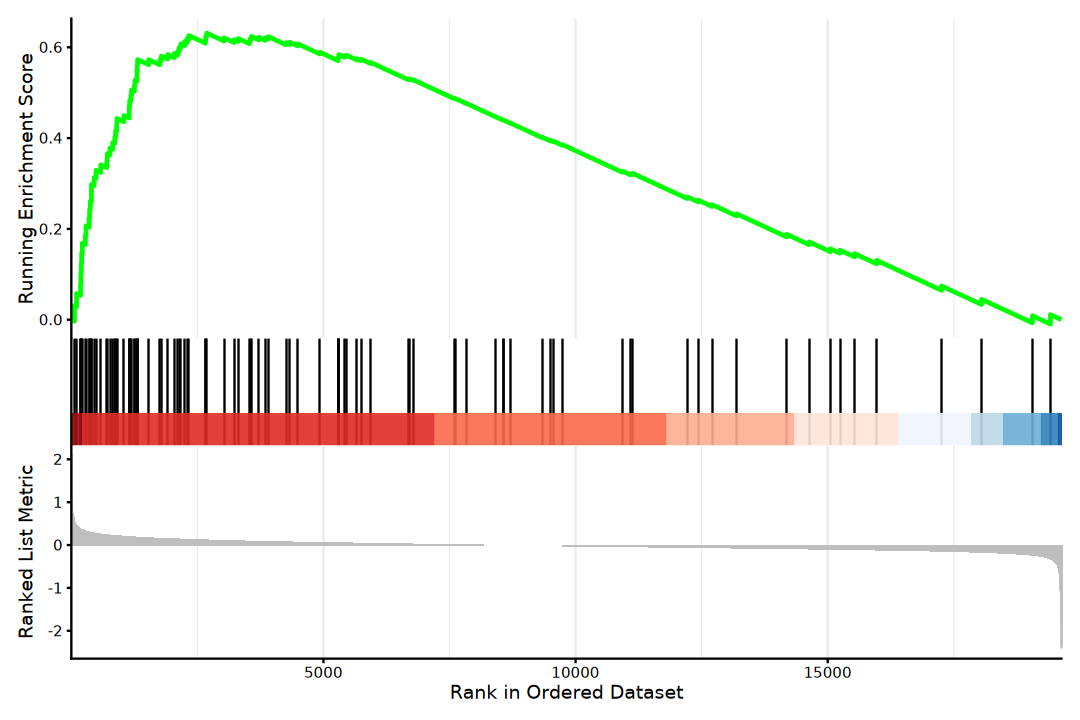

In [46]:
options(repr.plot.width = 9, repr.plot.height = 6)
gseaplot2(gsea_kegg, geneSetID = 1)

## Pathview

In [48]:
setwd(data_dir)
pathview(gene.data = gene_rank, 
    pathway.id = "00190", species = "hsa", 
    kegg.dir = "~/reference/Database/KEGG/pathview/hsa",
    limit = list(gene = max(abs(gene_rank)), cpd = 1))

Info: Downloading xml files for hsa00190, 1/1 pathways..

Info: Downloading png files for hsa00190, 1/1 pathways..

'select()' returned 1:1 mapping between keys and columns

Info: Working in directory /mnt/e/Dataset_1/expression_dataset/array/GSE62832

Info: Writing image file hsa00190.pathview.png



In [49]:
setwd(data_dir)
pathview(gene.data = gene_rank, 
    pathway.id = "04932", species = "hsa", 
    kegg.dir = "~/reference/Database/KEGG/pathview/hsa",
    limit = list(gene = max(abs(gene_rank)), cpd = 1))

Info: Downloading xml files for hsa04932, 1/1 pathways..

Info: Downloading png files for hsa04932, 1/1 pathways..

'select()' returned 1:1 mapping between keys and columns

Info: Working in directory /mnt/e/Dataset_1/expression_dataset/array/GSE62832

Info: Writing image file hsa04932.pathview.png

